<a href="https://colab.research.google.com/github/Dusyaant/FUNDAMENTALS-OF-MACHINE-LEARNING/blob/main/MLA0202_Lab_Exps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hypothesis History:
Step 1 (Yes): ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
Step 2 (Yes): ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Step 3 (No): ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
Step 4 (Yes): ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Final Most Specific Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


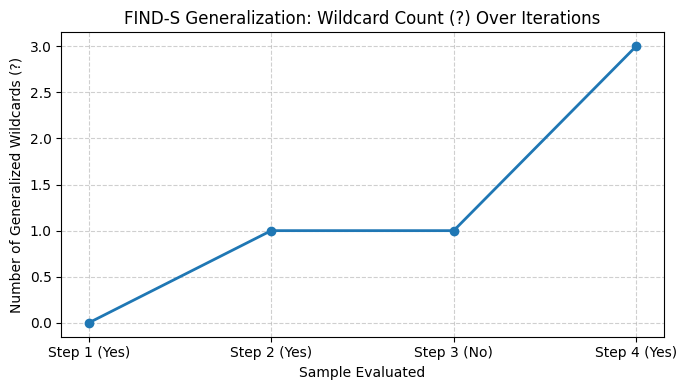

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Training Dataset (Classic EnjoySport dataset)
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)
features = df.iloc[:, :-1].values
target = df.iloc[:, -1].values

# 2. FIND-S Implementation
num_attributes = features.shape[1]
hypothesis = ['phi'] * num_attributes
history = []

for i, row in enumerate(features):
    if target[i] == 'Yes':
        if hypothesis[0] == 'phi':
            hypothesis = list(row)
        else:
            for j in range(num_attributes):
                if hypothesis[j] != row[j]:
                    hypothesis[j] = '?'
    history.append((f"Step {i+1} ({target[i]})", list(hypothesis)))

# 3. Output and Visualization
print("Hypothesis History:")
for step, h in history:
    print(f"{step}: {h}")
print("\nFinal Most Specific Hypothesis:", hypothesis)

# Visualizing hypothesis generalization progress
steps = [h[0] for h in history]
wildcards = [h[1].count('?') for h in history]

plt.figure(figsize=(7, 4))
plt.plot(steps, wildcards, marker='o', color='#1f77b4', linewidth=2)
plt.title('FIND-S Generalization: Wildcard Count (?) Over Iterations')
plt.xlabel('Sample Evaluated')
plt.ylabel('Number of Generalized Wildcards (?)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Final Specific Boundary (S): ['Sunny' 'Warm' '?' 'Strong' '?' '?']
Final General Boundary (G): [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]


AttributeError: 'Table' object has no attribute 'set_font_size'

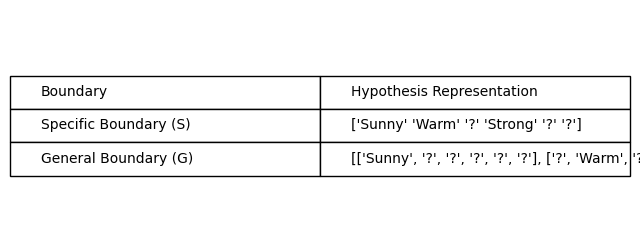

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'Target': ['Yes', 'Yes', 'No', 'Yes']
})

X = np.array(data.iloc[:, :-1])
Y = np.array(data.iloc[:, -1])

def candidate_elimination(concepts, target):
    specific_h = concepts[0].copy()
    general_h = [["?" for _ in range(len(specific_h))] for _ in range(len(specific_h))]

    for i, instance in enumerate(concepts):
        if target[i] == "Yes":
            for x in range(len(specific_h)):
                if instance[x] != specific_h[x]:
                    specific_h[x] = '?'
                    general_h[x][x] = '?'
        if target[i] == "No":
            for x in range(len(specific_h)):
                if instance[x] != specific_h[x]:
                    general_h[x][x] = specific_h[x]
                else:
                    general_h[x][x] = '?'

    general_h = [g for g in general_h if g != ['?' for _ in range(len(specific_h))]]
    return specific_h, general_h

s_final, g_final = candidate_elimination(X, Y)

print("Final Specific Boundary (S):", s_final)
print("Final General Boundary (G):", g_final)

# Textual Boundary Visualization Plot for Lab Screenshots
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis('off')
table_data = [
    ["Boundary", "Hypothesis Representation"],
    ["Specific Boundary (S)", str(s_final)],
    ["General Boundary (G)", str(g_final)]
]
table = ax.table(cellText=table_data, loc='center', cellLoc='left')
table.scale(1, 2)
table.auto_set_font_size(False)
table.set_font_size(10)
plt.title("Candidate-Elimination: Version Space Boundaries", fontsize=12, pad=20)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(


Prediction for ['Sunny', 'Cool', 'High', 'Strong']: Do Not Play (No)


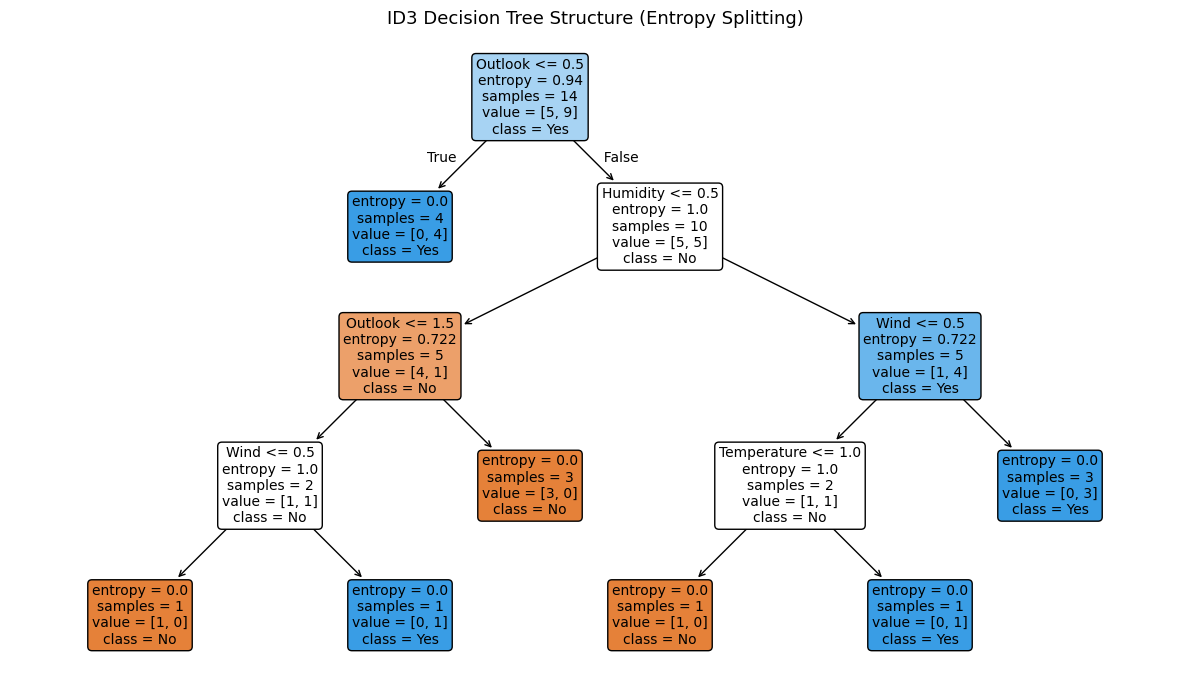

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder

# 1. Dataset: Play Tennis Decision Problem
tennis_data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rainy', 'Rainy', 'Rainy', 'Overcast', 'Sunny', 'Sunny', 'Rainy', 'Sunny', 'Overcast', 'Overcast', 'Rainy'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(tennis_data)

# 2. Encoding categorical attributes into numeric identifiers
encoder = OrdinalEncoder()
X = encoder.fit_transform(df[['Outlook', 'Temperature', 'Humidity', 'Wind']])
y = df['PlayTennis'].apply(lambda x: 1 if x == 'Yes' else 0)

# 3. Fit ID3-equivalent Decision Tree (using entropy criterion)
dt_clf = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_clf.fit(X, y)

# 4. Classify a new test sample: [Sunny, Cool, High, Strong]
new_sample = encoder.transform([['Sunny', 'Cool', 'High', 'Strong']])
prediction = dt_clf.predict(new_sample)
print(f"Prediction for ['Sunny', 'Cool', 'High', 'Strong']: {'Play (Yes)' if prediction[0] == 1 else 'Do Not Play (No)'}")

# 5. Plot the complete Decision Tree
plt.figure(figsize=(12, 7))
plot_tree(
    dt_clf,
    feature_names=['Outlook', 'Temperature', 'Humidity', 'Wind'],
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("ID3 Decision Tree Structure (Entropy Splitting)", fontsize=13)
plt.tight_layout()
plt.show()

Classification for sample {'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}: PlayTennis = No


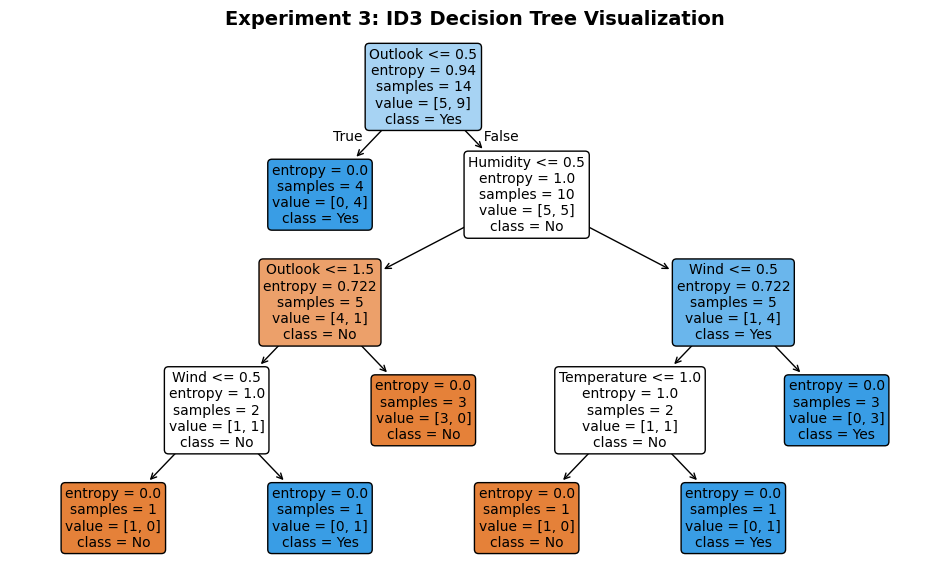

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder

# 1. Classic Weather/PlayTennis Dataset
dataset = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast', 'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(dataset)

# 2. Encode categorical variables to numeric values
encoder = OrdinalEncoder()
X = encoder.fit_transform(df[['Outlook', 'Temperature', 'Humidity', 'Wind']])
y = df['PlayTennis'].map({'No': 0, 'Yes': 1})

# 3. Train Decision Tree using 'entropy' (the criterion of the ID3 algorithm)
clf = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf.fit(X, y)

# 4. Classify a new sample: [Sunny, Cool, High, Strong]
new_sample = pd.DataFrame([['Sunny', 'Cool', 'High', 'Strong']], columns=['Outlook', 'Temperature', 'Humidity', 'Wind'])
new_sample_encoded = encoder.transform(new_sample)
prediction = clf.predict(new_sample_encoded)
class_result = 'Yes' if prediction[0] == 1 else 'No'

print(f"Classification for sample {new_sample.to_dict(orient='records')[0]}: PlayTennis = {class_result}")

# 5. Visualizing the Decision Tree (Output Screenshot for Lab Report)
plt.figure(figsize=(12, 7))
plot_tree(
    clf,
    feature_names=['Outlook', 'Temperature', 'Humidity', 'Wind'],
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Experiment 3: ID3 Decision Tree Visualization", fontsize=14, weight='bold')
plt.savefig("exp3_decision_tree.png", dpi=300, bbox_inches='tight')
plt.show()

--- Backpropagation Training Complete ---
Target Output:
 [0 1 1 0]
Network Predictions:
 [0.0142 0.9906 0.979  0.0186]


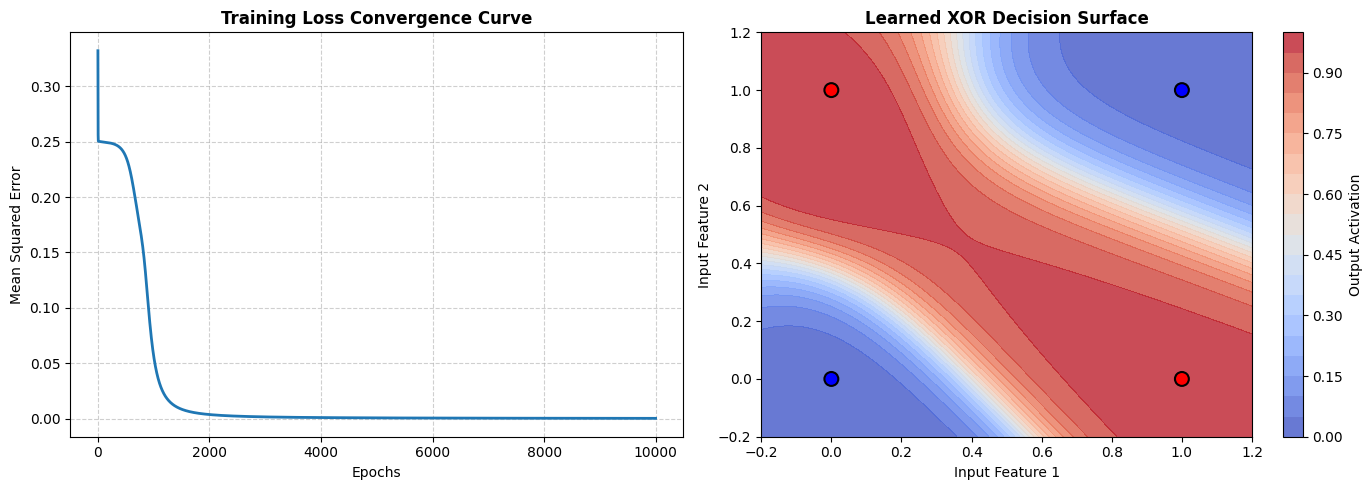

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Sigmoid activation function and its derivative
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1.0 - x)

# 2. XOR Training Dataset (Linearly non-separable)
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

y = np.array([[0], [1], [1], [0]])

# 3. Network Architecture: 2 inputs -> 4 hidden neurons -> 1 output neuron
np.random.seed(42)
input_dim = 2
hidden_dim = 4
output_dim = 1
learning_rate = 0.5
epochs = 10000

weights_hidden = np.random.uniform(size=(input_dim, hidden_dim))
bias_hidden = np.random.uniform(size=(1, hidden_dim))
weights_output = np.random.uniform(size=(hidden_dim, output_dim))
bias_output = np.random.uniform(size=(1, output_dim))

loss_history = []

# 4. Training Loop: Forward Propagation & Backpropagation
for epoch in range(epochs):
    # Forward Pass
    hidden_linear = np.dot(X, weights_hidden) + bias_hidden
    hidden_output = sigmoid(hidden_linear)

    final_linear = np.dot(hidden_output, weights_output) + bias_output
    predicted_output = sigmoid(final_linear)

    # Compute MSE Loss
    loss = np.mean(np.square(y - predicted_output))
    loss_history.append(loss)

    # Backward Pass (Chain Rule)
    error_output = y - predicted_output
    d_predicted_output = error_output * sigmoid_derivative(predicted_output)

    error_hidden = d_predicted_output.dot(weights_output.T)
    d_hidden_output = error_hidden * sigmoid_derivative(hidden_output)

    # Weight Updates
    weights_output += hidden_output.T.dot(d_predicted_output) * learning_rate
    bias_output += np.sum(d_predicted_output, axis=0, keepdims=True) * learning_rate
    weights_hidden += X.T.dot(d_hidden_output) * learning_rate
    bias_hidden += np.sum(d_hidden_output, axis=0, keepdims=True) * learning_rate

print("--- Backpropagation Training Complete ---")
print("Target Output:\n", y.flatten())
print("Network Predictions:\n", np.round(predicted_output.flatten(), 4))

# 5. Visualizing Loss Convergence and Decision Surface
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss Convergence
ax1.plot(loss_history, color='#1f77b4', lw=2)
ax1.set_title("Training Loss Convergence Curve", fontsize=12, weight='bold')
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Mean Squared Error")
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Learned Non-Linear Decision Boundary
xx, yy = np.meshgrid(np.linspace(-0.2, 1.2, 200), np.linspace(-0.2, 1.2, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_hidden = sigmoid(np.dot(grid_points, weights_hidden) + bias_hidden)
grid_pred = sigmoid(np.dot(grid_hidden, weights_output) + bias_output).reshape(xx.shape)

contour = ax2.contourf(xx, yy, grid_pred, levels=20, cmap='coolwarm', alpha=0.8)
ax2.scatter(X[:, 0], X[:, 1], c=y.flatten(), cmap='bwr', edgecolors='k', s=100, linewidth=1.5)
ax2.set_title("Learned XOR Decision Surface", fontsize=12, weight='bold')
ax2.set_xlabel("Input Feature 1")
ax2.set_ylabel("Input Feature 2")
fig.colorbar(contour, ax=ax2, label="Output Activation")

plt.tight_layout()
plt.savefig("exp4_backpropagation_results.png", dpi=300, bbox_inches='tight')
plt.show()

--- Logistic Regression Metrics ---
Weights (w1, w2): [0.92007847 2.68693739]
Bias (b):         -0.9506
Accuracy:         86.67%
Log Loss:         0.4023


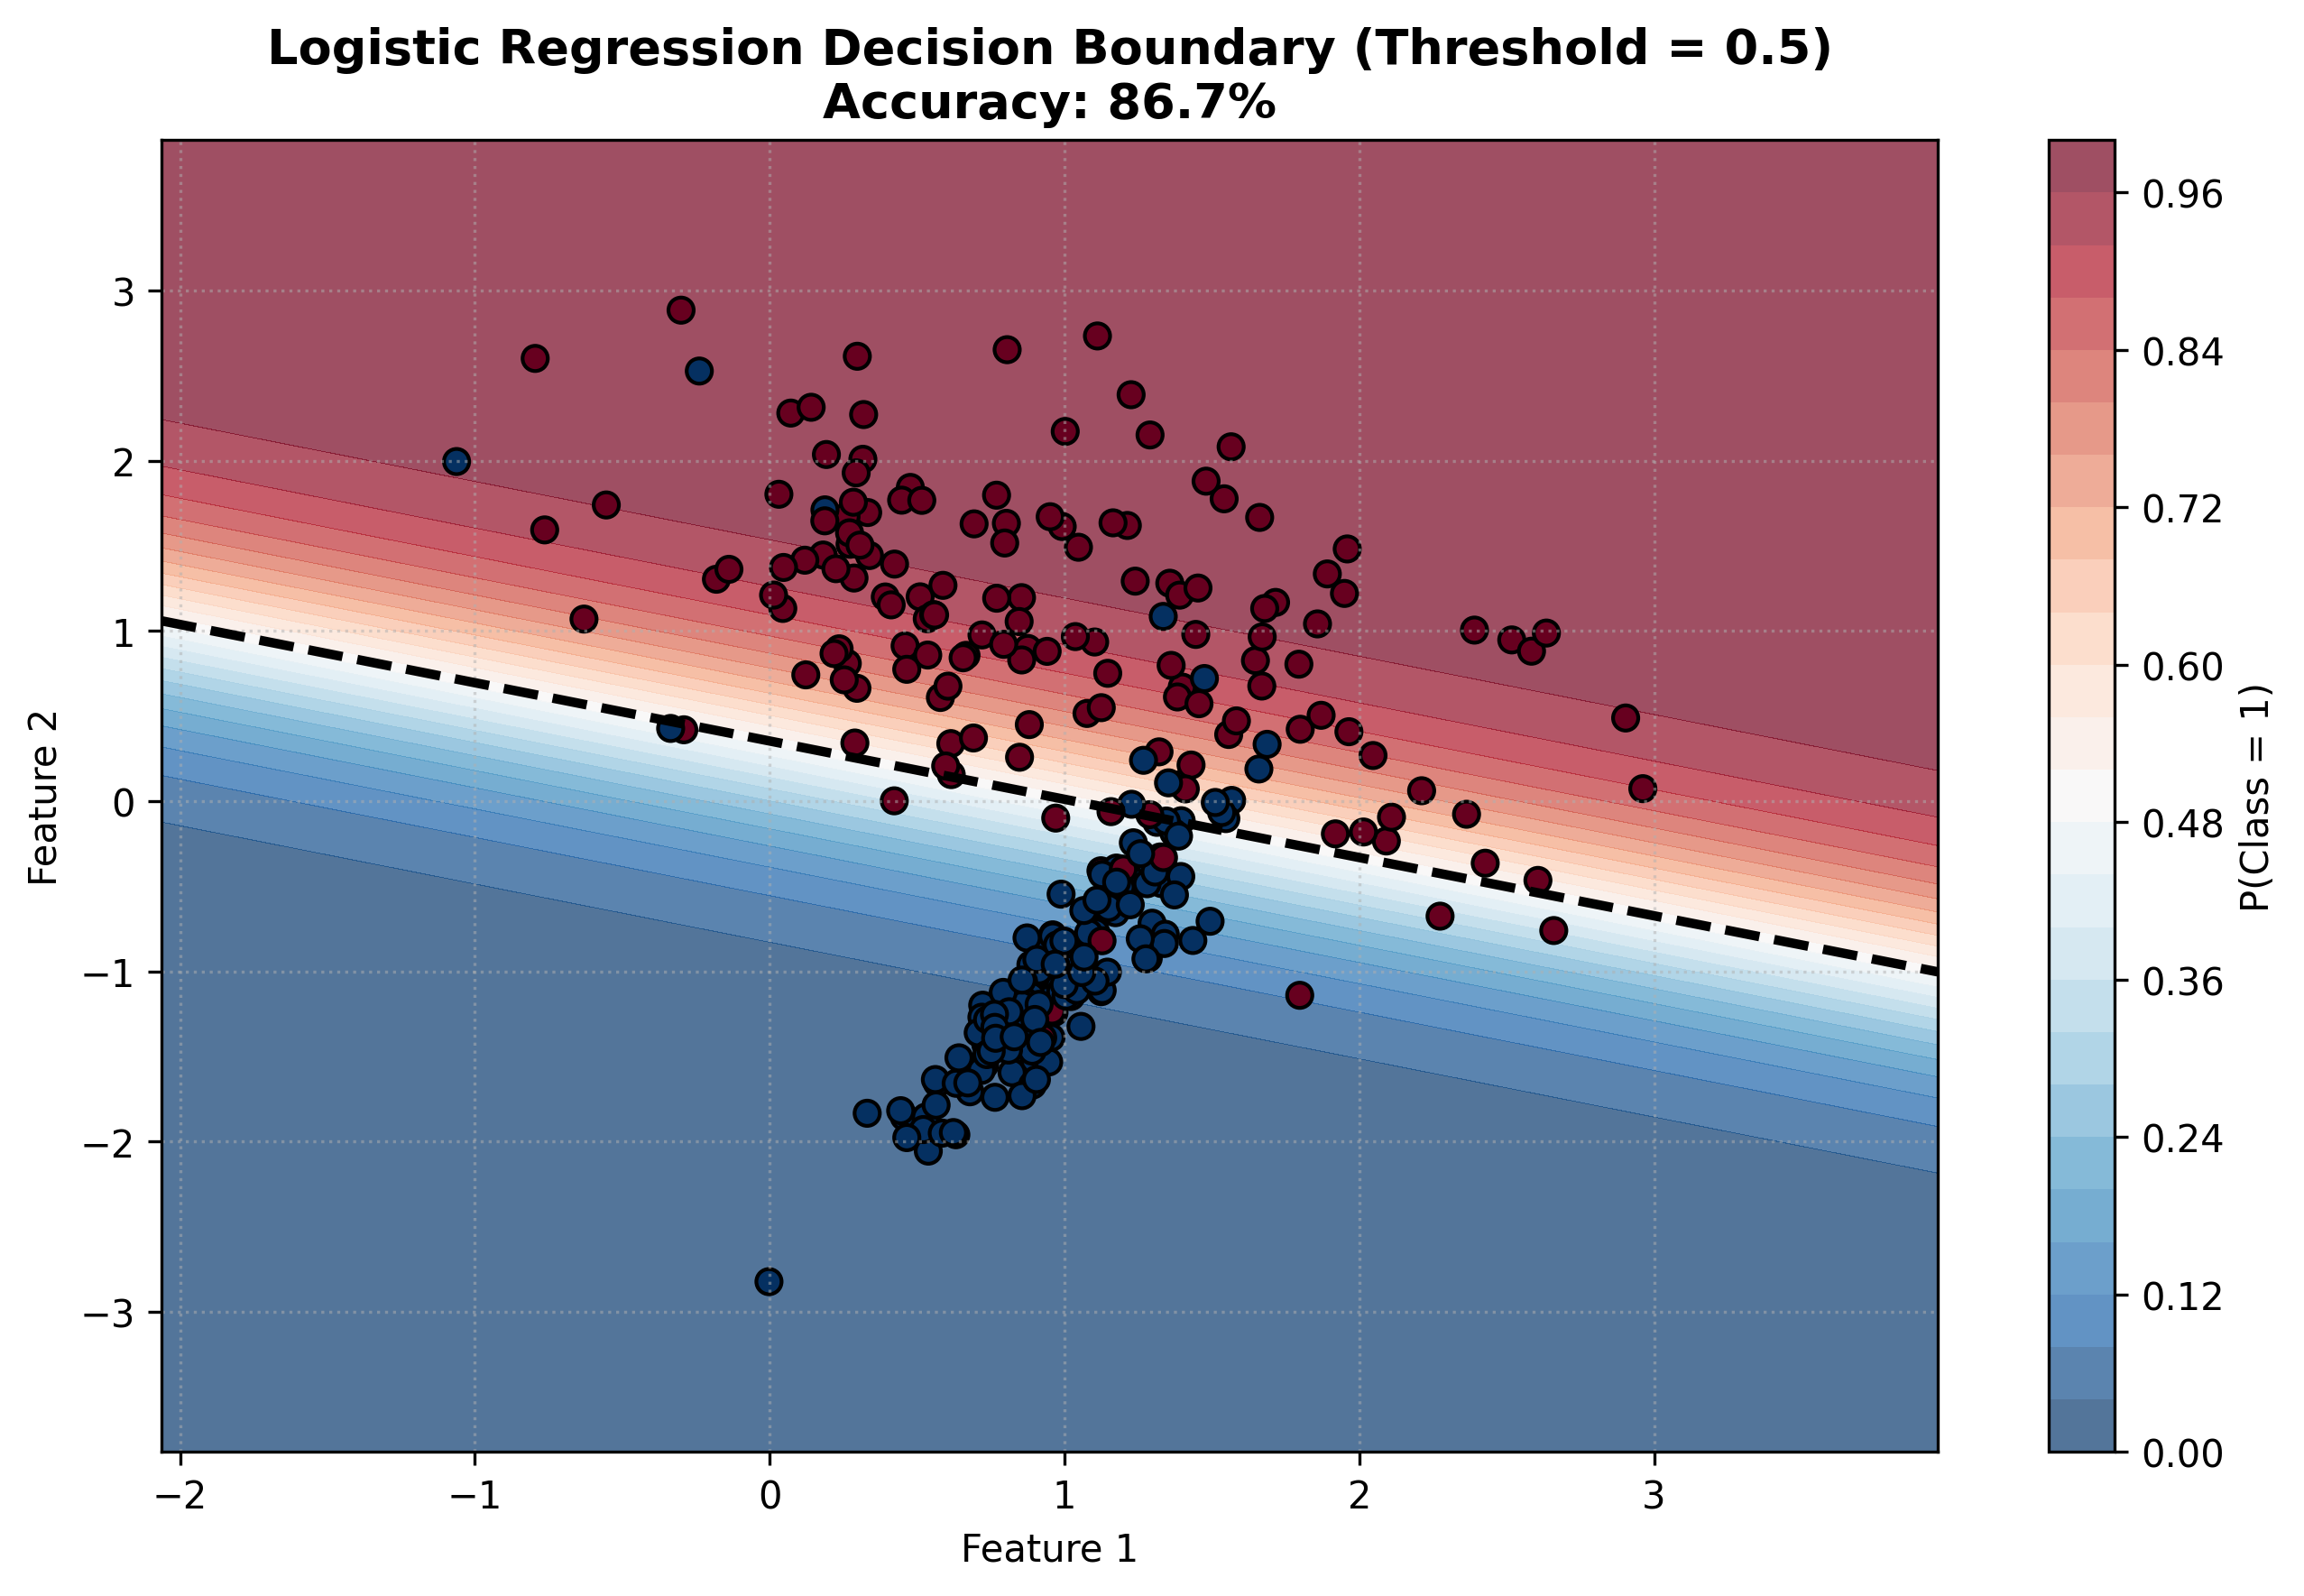

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

# 1. Generate 2D binary classification dataset
X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    flip_y=0.05,
    random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 2. Fit Logistic Regression
lr_clf = LogisticRegression(solver='lbfgs', random_state=42)
lr_clf.fit(X_train, y_train)

# 3. Model Evaluation
y_pred = lr_clf.predict(X_test)
y_prob = lr_clf.predict_proba(X_test)
acc = accuracy_score(y_test, y_pred)
loss = log_loss(y_test, y_prob)

print("--- Logistic Regression Metrics ---")
print(f"Weights (w1, w2): {lr_clf.coef_[0]}")
print(f"Bias (b):         {lr_clf.intercept_[0]:.4f}")
print(f"Accuracy:         {acc * 100:.2f}%")
print(f"Log Loss:         {loss:.4f}")

# 4. Visualizing Probability Heatmap and Linear Decision Boundary
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Predict class probabilities over grid
grid = np.c_[xx.ravel(), yy.ravel()]
probs = lr_clf.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(9, 6), dpi=300)
contour = plt.contourf(xx, yy, probs, levels=25, cmap='RdBu_r', alpha=0.7)
plt.colorbar(contour, label='P(Class = 1)')

# Plot linear decision boundary (P = 0.5)
plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=2.5, linestyles='--')

scatter = plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdBu_r', edgecolors='k', s=45)
plt.title(f"Logistic Regression Decision Boundary (Threshold = 0.5)\nAccuracy: {acc * 100:.1f}%", fontsize=13, weight='bold')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("exp7_logistic_regression.png", bbox_inches='tight')
plt.show()

--- Linear Regression Results ---
Learned Slope (w1):      3.0916 (True: 3.0)
Learned Intercept (w0):  3.9553 (True: 4.0)
Mean Squared Error:      0.5338
R² Score:                0.8662


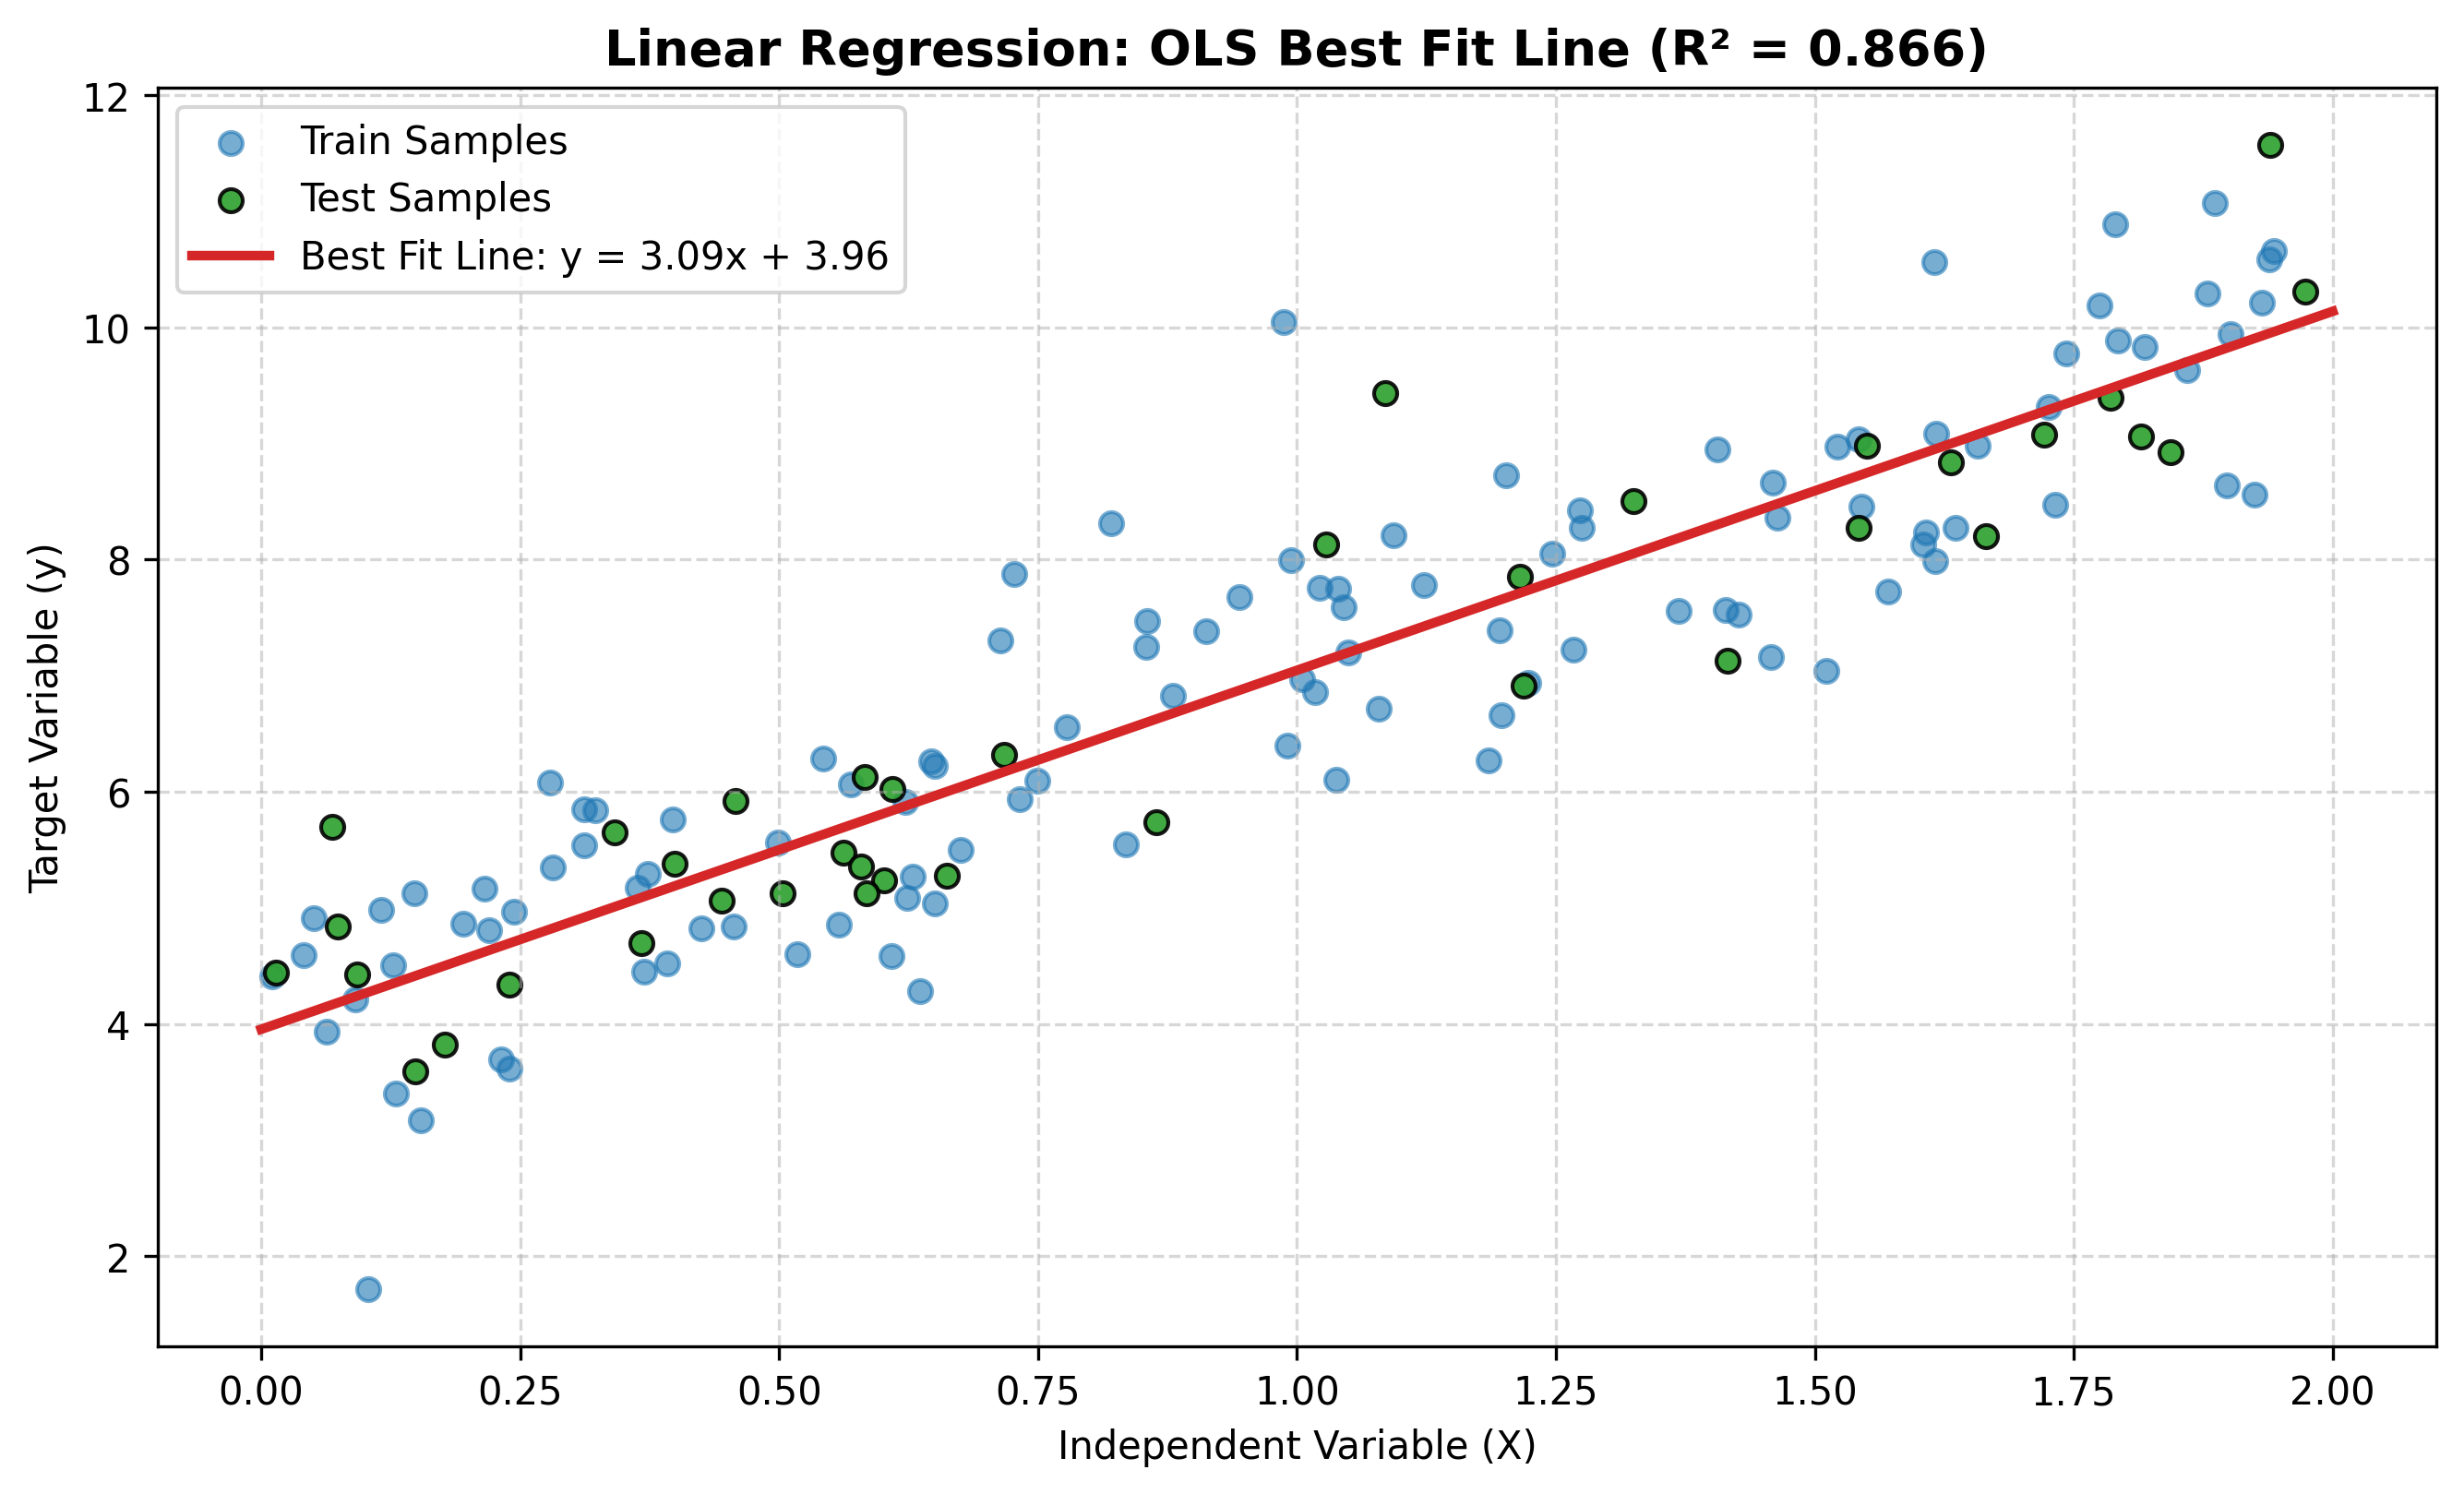

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Synthesize 1D continuous data with Gaussian noise
np.random.seed(42)
X = 2 * np.random.rand(150, 1)
y = 4 + 3 * X + np.random.randn(150, 1) * 0.8  # Ground Truth: slope=3, intercept=4

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 2. Fit Linear Regression Model via OLS
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# 3. Model Predictions & Evaluation
y_pred = lin_reg.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Linear Regression Results ---")
print(f"Learned Slope (w1):      {lin_reg.coef_[0][0]:.4f} (True: 3.0)")
print(f"Learned Intercept (w0):  {lin_reg.intercept_[0]:.4f} (True: 4.0)")
print(f"Mean Squared Error:      {mse:.4f}")
print(f"R² Score:                {r2:.4f}")

# 4. Visualizing Best Fit Line and Residuals
X_domain = np.linspace(0, 2, 200).reshape(-1, 1)
y_domain_pred = lin_reg.predict(X_domain)

plt.figure(figsize=(9, 5.5), dpi=300)
plt.scatter(X_train, y_train, color='#1f77b4', alpha=0.6, label='Train Samples')
plt.scatter(X_test, y_test, color='#2ca02c', alpha=0.9, edgecolors='k', label='Test Samples')
plt.plot(X_domain, y_domain_pred, color='#d62728', linewidth=2.5, label=f'Best Fit Line: y = {lin_reg.coef_[0][0]:.2f}x + {lin_reg.intercept_[0]:.2f}')

plt.title(f"Linear Regression: OLS Best Fit Line (R² = {r2:.3f})", fontsize=13, weight='bold')
plt.xlabel("Independent Variable (X)")
plt.ylabel("Target Variable (y)")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("exp8_linear_regression.png", bbox_inches='tight')
plt.show()

Polynomial Degree  1 -> Train MSE: 1.8941
Polynomial Degree  2 -> Train MSE: 0.3655
Polynomial Degree 14 -> Train MSE: 0.3003


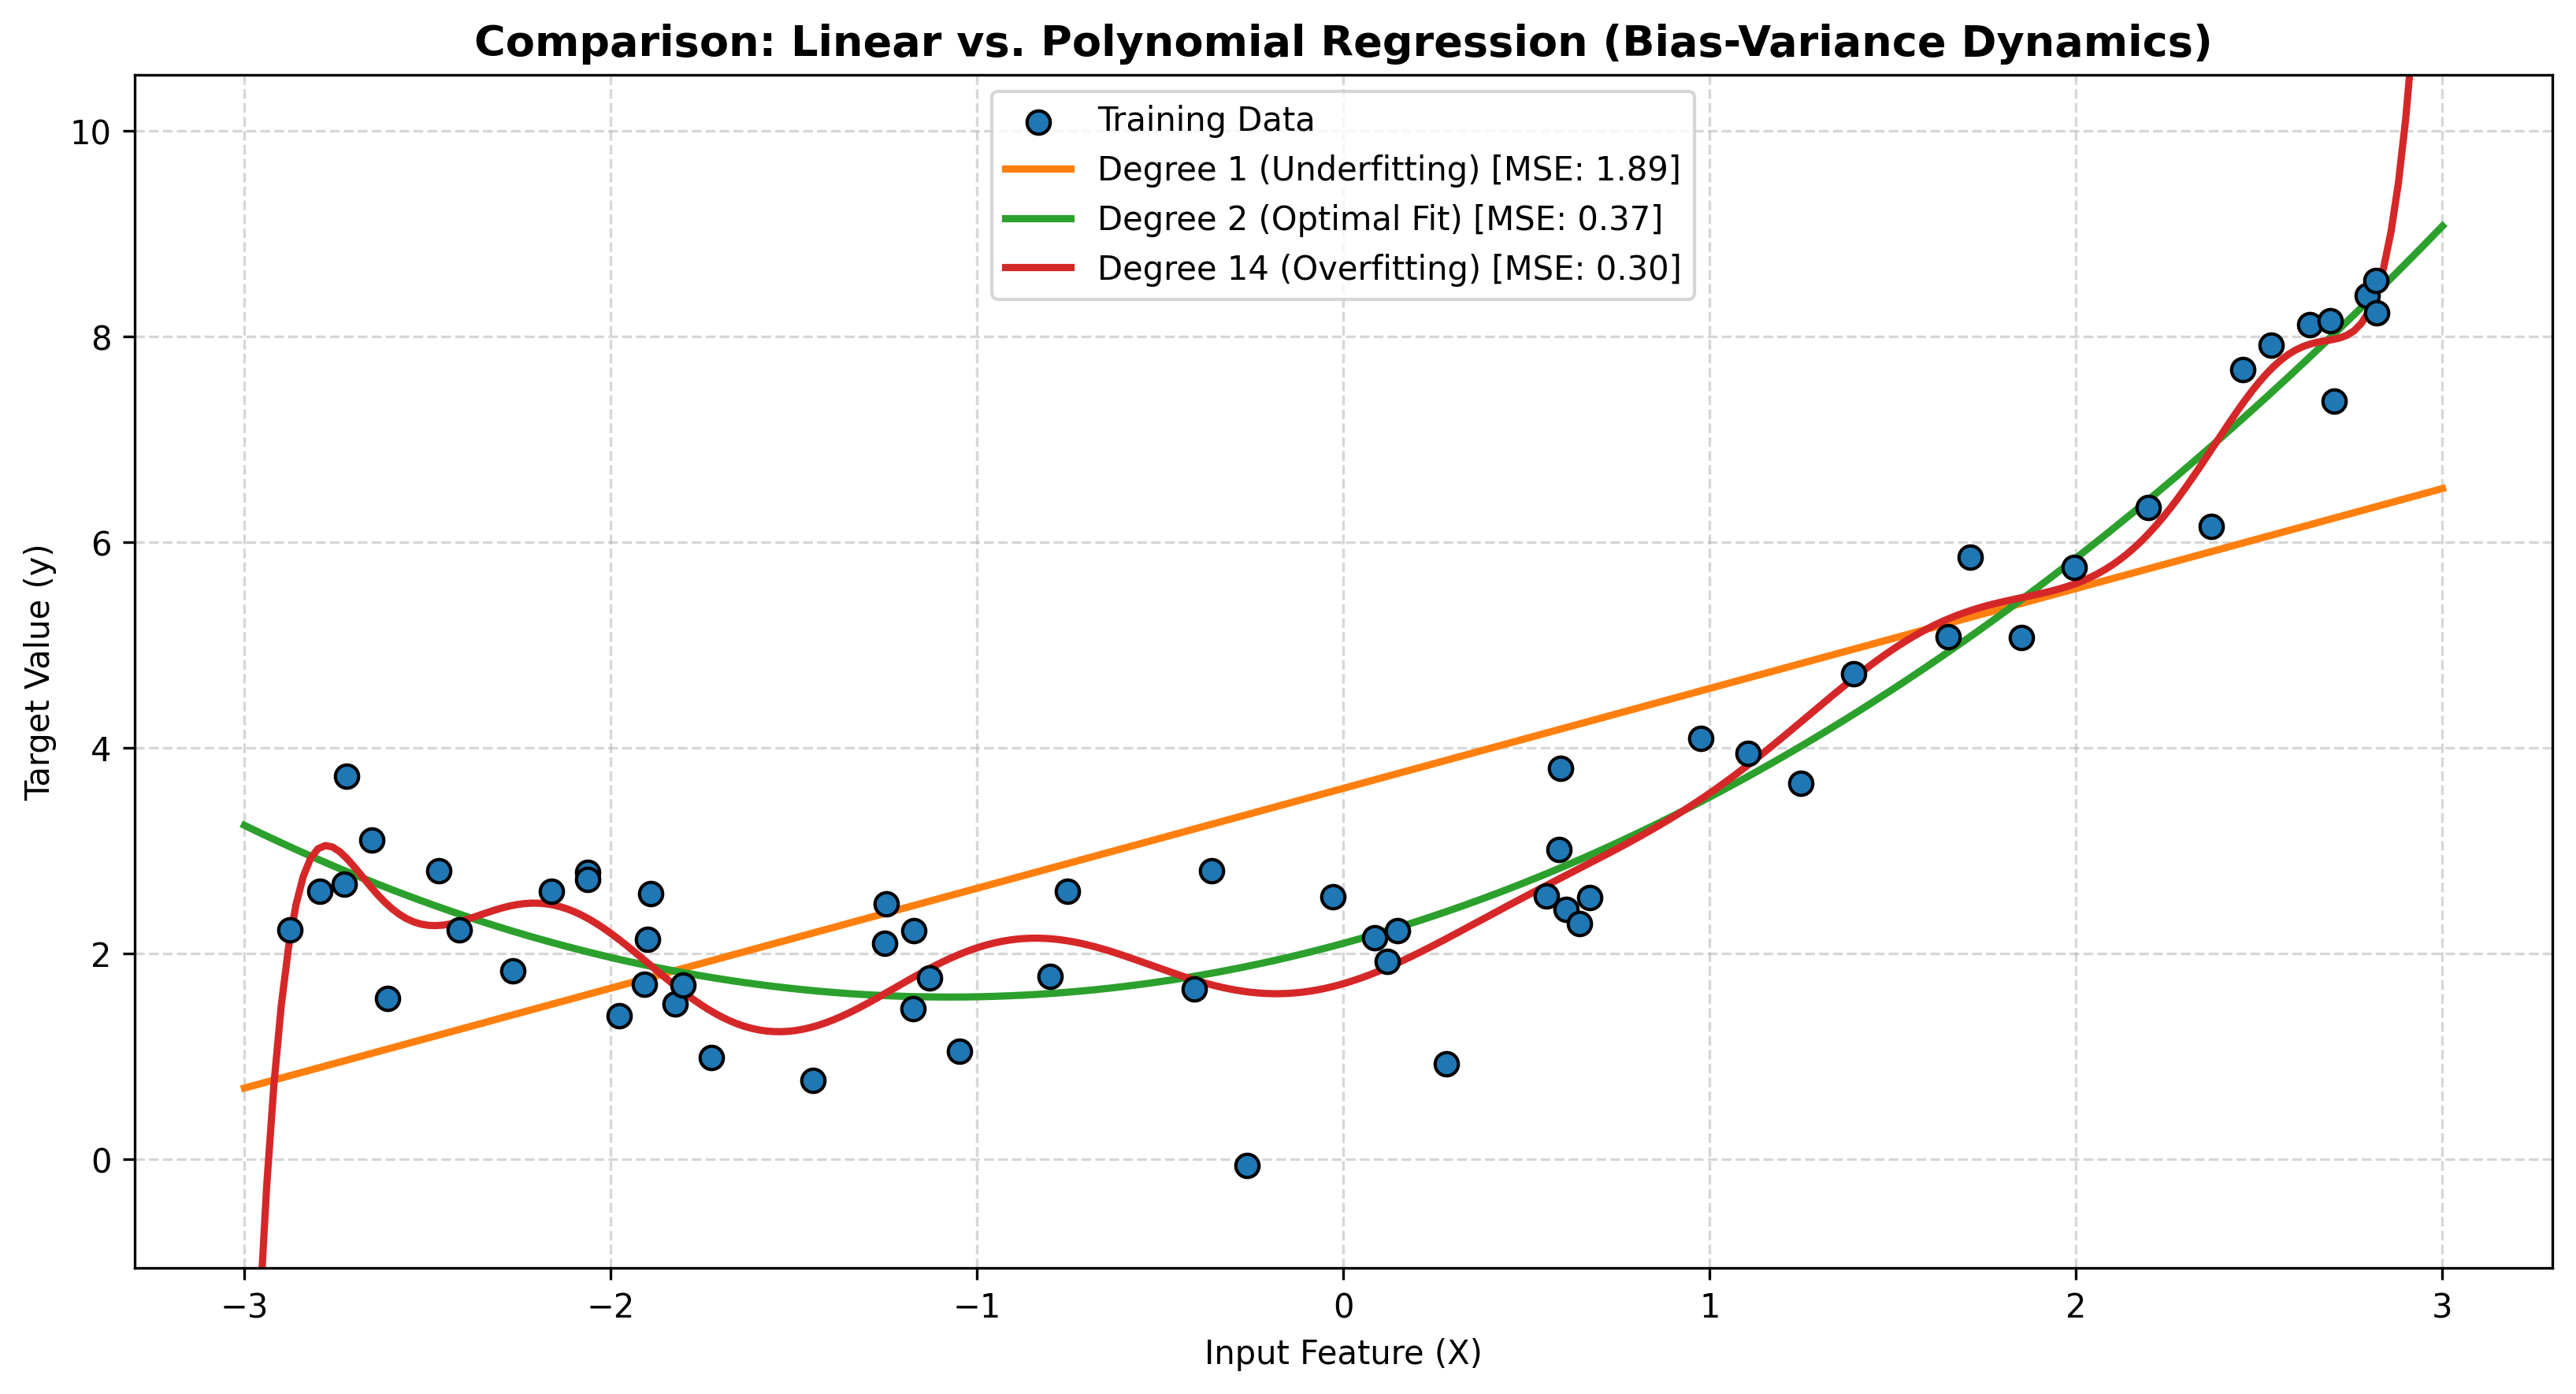

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Generate Non-linear Quadratic Dataset
np.random.seed(42)
m = 60
X = np.sort(np.random.uniform(-3, 3, (m, 1)), axis=0)
y = 0.5 * X**2 + X + 2 + np.random.randn(m, 1) * 0.7  # True model: y = 0.5x^2 + x + 2

# 2. Compare Degrees: Degree 1 (Linear), Degree 2 (Quadratic), Degree 14 (Overfit)
degrees = [1, 2, 14]
colors = ['#ff7f0e', '#2ca02c', '#d62728']
labels = ['Degree 1 (Underfitting)', 'Degree 2 (Optimal Fit)', 'Degree 14 (Overfitting)']

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.figure(figsize=(11, 6), dpi=300)
plt.scatter(X, y, color='#1f77b4', edgecolors='k', s=50, label='Training Data', zorder=5)

for degree, color, label in zip(degrees, colors, labels):
    # Expand features to polynomial powers
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly_features.fit_transform(X)
    X_plot_poly = poly_features.transform(X_plot)

    # Train linear model on polynomial features
    model = LinearRegression()
    model.fit(X_poly, y)

    y_train_pred = model.predict(X_poly)
    y_plot_pred = model.predict(X_plot_poly)
    mse = mean_squared_error(y, y_train_pred)

    print(f"Polynomial Degree {degree:2d} -> Train MSE: {mse:.4f}")
    plt.plot(X_plot, y_plot_pred, color=color, linewidth=2.2, label=f"{label} [MSE: {mse:.2f}]")

plt.ylim(np.min(y) - 1, np.max(y) + 2)
plt.title("Comparison: Linear vs. Polynomial Regression (Bias-Variance Dynamics)", fontsize=13, weight='bold')
plt.xlabel("Input Feature (X)")
plt.ylabel("Target Value (y)")
plt.legend(loc='upper center', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("exp9_linear_vs_polynomial.png", bbox_inches='tight')
plt.show()

--- Expectation-Maximization (GMM) Results ---
Converged:             True
Iterations completed:  2
Lower Bound Log-Lik:   -2.0199

Cluster 0 Weight (pi): 0.335 | Mean: [-5.16   8.778]
Cluster 1 Weight (pi): 0.333 | Mean: [-1.408 -1.33 ]
Cluster 2 Weight (pi): 0.333 | Mean: [ 2.031 -1.262]


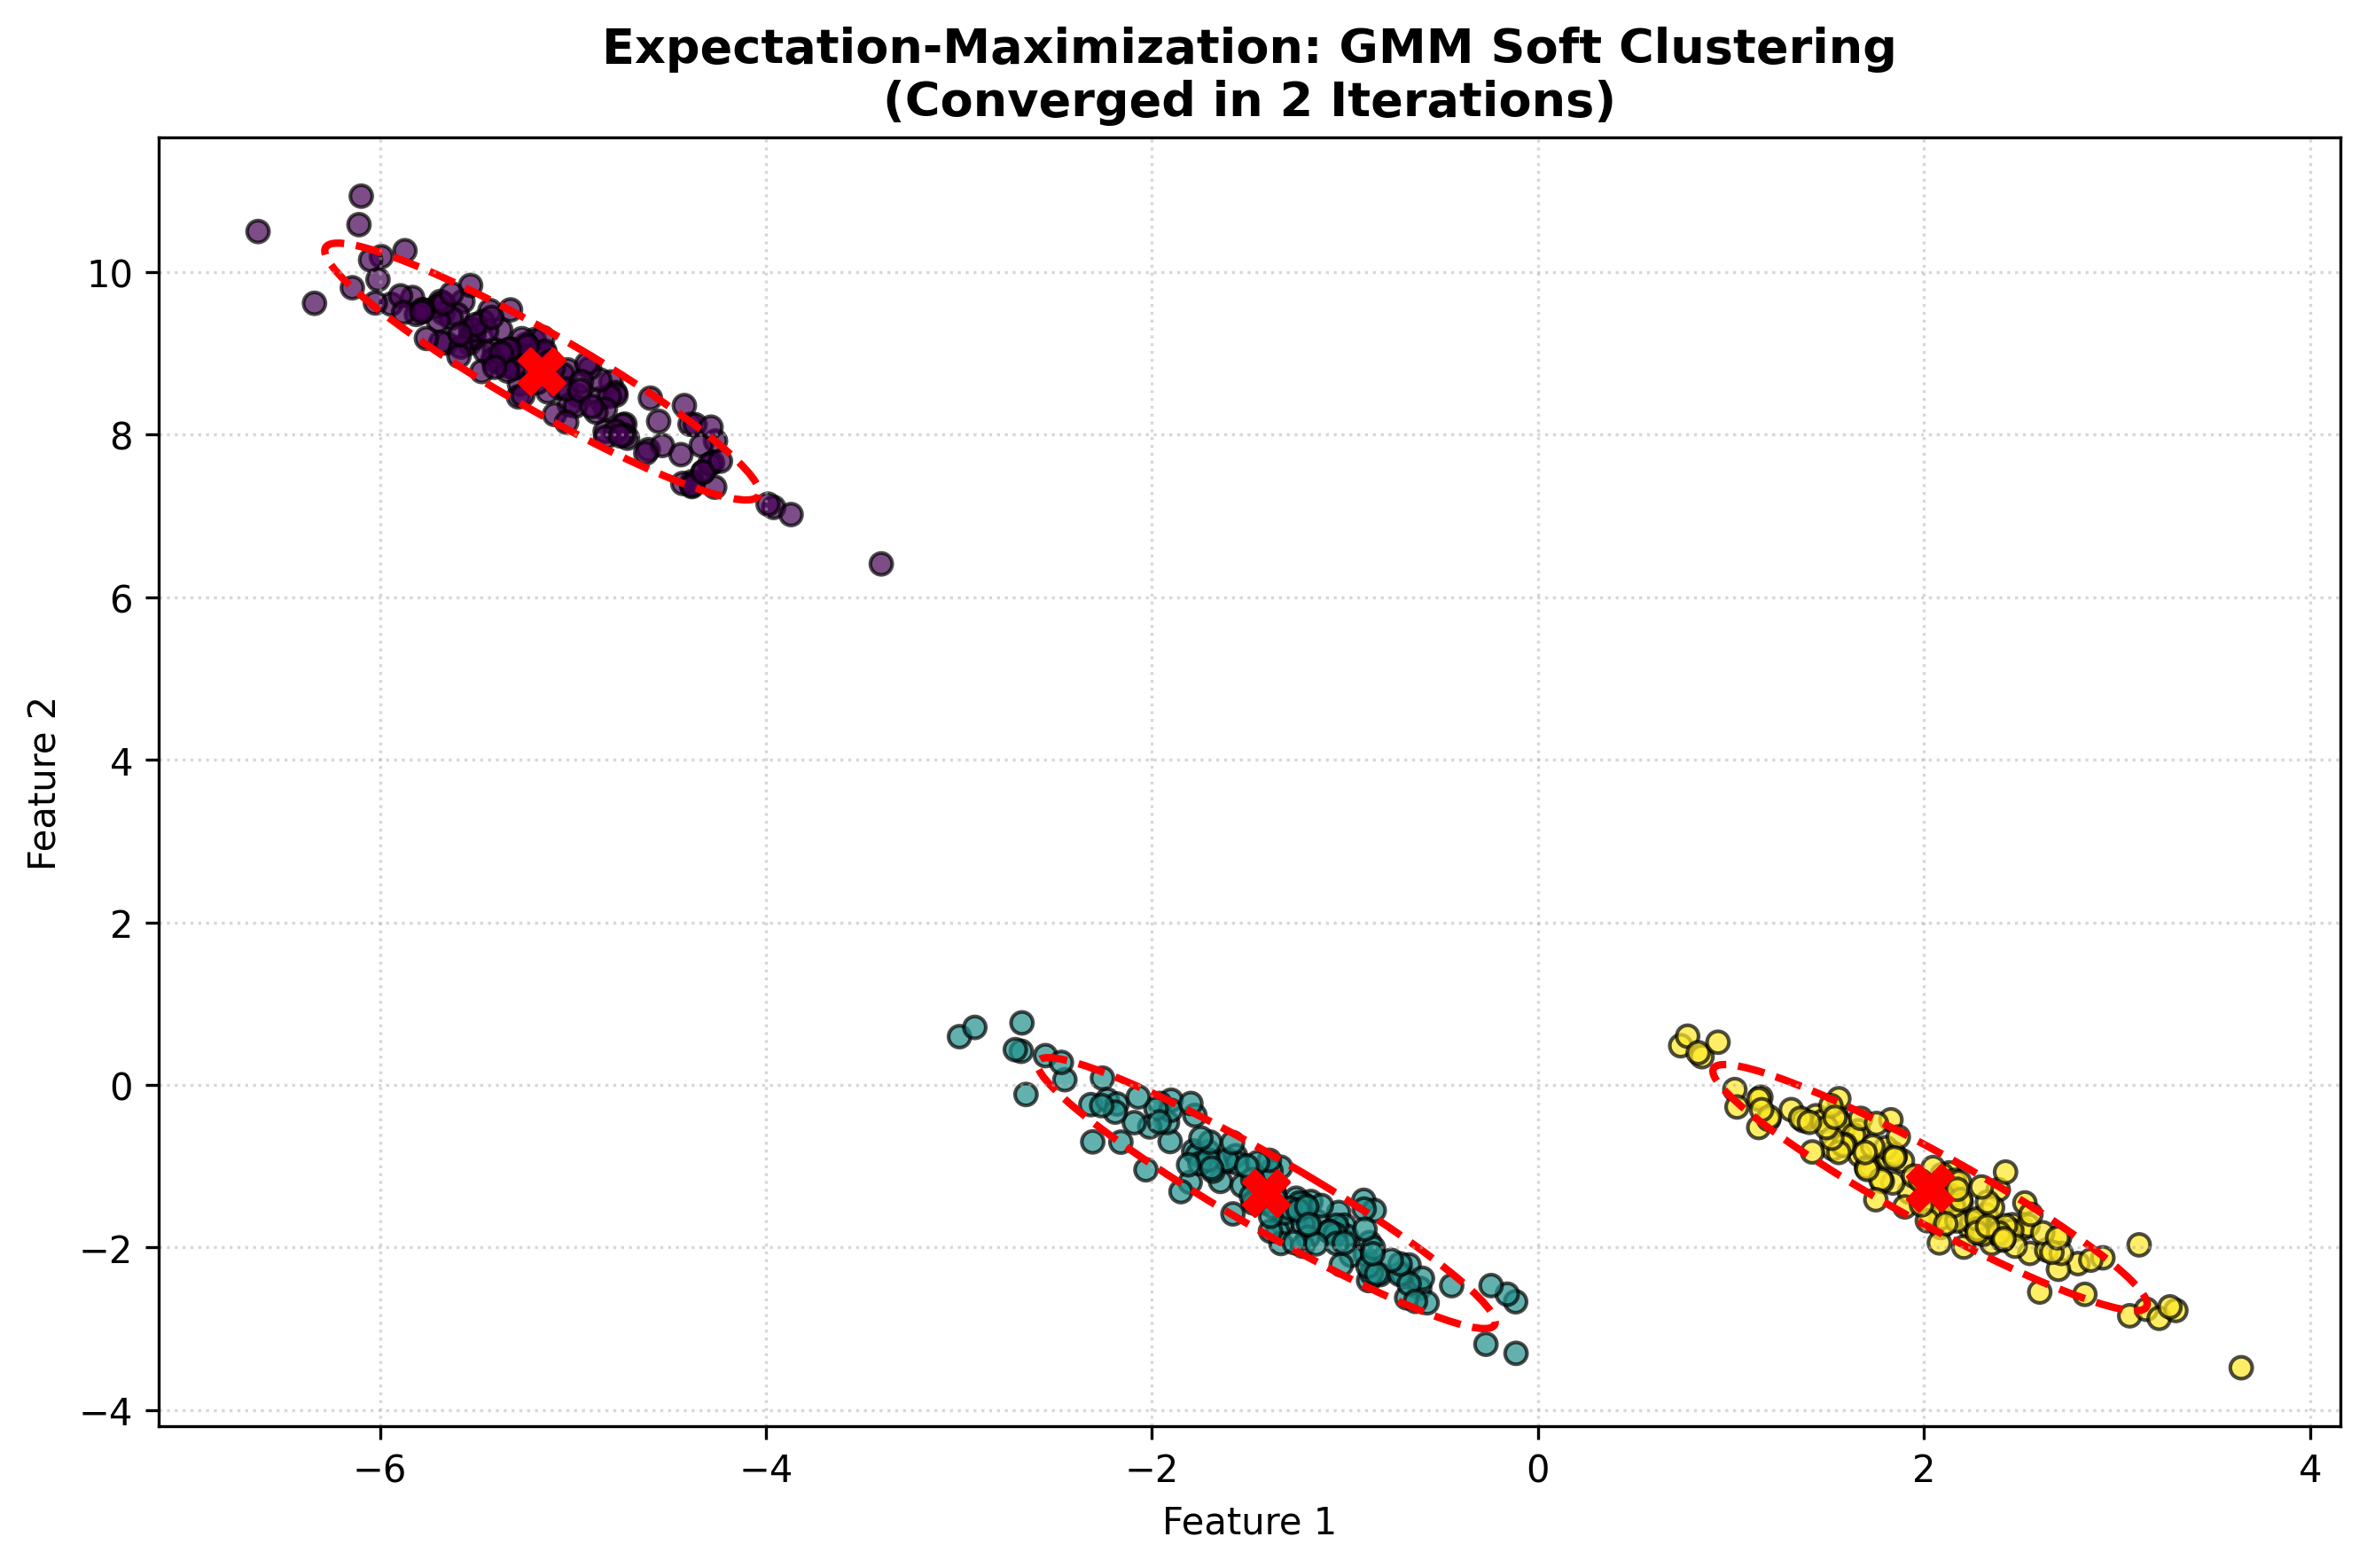

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

# 1. Generate anisotropic / non-spherical clusters
np.random.seed(42)
X, y_true = make_blobs(n_samples=400, centers=3, cluster_std=0.8, random_state=42)
# Apply transformation to elongate clusters
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X = np.dot(X, transformation)

# 2. Fit Gaussian Mixture Model using Expectation-Maximization
n_components = 3
gmm = GaussianMixture(n_components=n_components, covariance_type='full', max_iter=200, random_state=42)
gmm.fit(X)

# Soft probabilities and cluster labels
cluster_labels = gmm.predict(X)
responsibilities = gmm.predict_proba(X)

print("--- Expectation-Maximization (GMM) Results ---")
print(f"Converged:             {gmm.converged_}")
print(f"Iterations completed:  {gmm.n_iter_}")
print(f"Lower Bound Log-Lik:   {gmm.lower_bound_:.4f}\n")
for k in range(n_components):
    print(f"Cluster {k} Weight (pi): {gmm.weights_[k]:.3f} | Mean: {gmm.means_[k].round(3)}")

# 3. Helper function to draw covariance confidence ellipses
def draw_ellipse(position, covariance, ax, color):
    vals, vecs = np.linalg.eigh(covariance)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

    # 2 standard deviations contour (~95% confidence interval)
    w, h = 2 * 2 * np.sqrt(vals)
    ellip = Ellipse(xy=position, width=w, height=h, angle=theta,
                    edgecolor=color, facecolor='none', linestyle='--', linewidth=2)
    ax.add_patch(ellip)

# 4. Visualizing EM Gaussian Components and Clustering for Lab Report
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
scatter = ax.scatter(X[:, 0], X[:, 1], c=cluster_labels, cmap='viridis', s=35, alpha=0.7, edgecolors='k')

colors = ['#440154', '#21918c', '#fde725']
for i in range(n_components):
    draw_ellipse(gmm.means_[i], gmm.covariances_[i], ax, color='red')
    ax.scatter(gmm.means_[i, 0], gmm.means_[i, 1], c='red', marker='X', s=150, zorder=10)

plt.title(f"Expectation-Maximization: GMM Soft Clustering\n(Converged in {gmm.n_iter_} Iterations)", fontsize=13, weight='bold')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig("exp10_expectation_maximization.png", bbox_inches='tight')
plt.show()